# Chapitre 6 — calcul scientifique, concurrence et pandas

## Objectif

Résoudre des problèmes numériques, choisir une organisation du calcul, puis préparer et résumer une table de commandes. Ce notebook accompagne les 59 diapositives. Les données sont fictives et créées dans les cellules ; aucun service réseau n'est utilisé.

Les exercices précèdent leurs corrections. Pour chaque exercice, écrire d'abord les étapes et prévoir un résultat sur un petit exemple. Les sorties enregistrées permettent ensuite de relire les calculs.

## Préparation

Installer, dans le même environnement Python : numpy, scipy, pandas et matplotlib. Dans le terminal : python -m pip install numpy scipy pandas matplotlib. Dans Jupyter, une cellule %pip install numpy scipy pandas matplotlib permet aussi l'installation.

Utiliser un noyau Python avec la prise en charge de await, comme Jupyter/IPython. Exécuter les cellules dans l'ordre. Le code de lancement des processus est fourni et crée ses fichiers dans un dossier temporaire ; aucune modification manuelle de chemin n'est nécessaire. Les fichiers Python du pack permettent également un lancement dans un terminal.

Les graphiques sont fournis pour lire les résultats ; la syntaxe de Matplotlib n'est pas un objectif de ce chapitre.


## Diapositive 3 — Environnement de travail

Exécuter les cellules dans l'ordre. Les données sont créées localement et aucun service distant n'est appelé. Les versions utilisées s'affichent ci-dessous.

In [1]:
import numpy as np
import scipy
import pandas as pd
from scipy import optimize, stats
print(np.__version__, scipy.__version__, pd.__version__)

2.3.5 1.18.1 2.2.3


In [2]:
import matplotlib.pyplot as plt
burgundy, ink = "#8C1515", "#2E2D29"
plt.rcParams.update({"figure.dpi":120, "font.size":11,
    "axes.spines.top":False, "axes.spines.right":False,
    "axes.grid":True, "grid.alpha":0.15,
    "figure.constrained_layout.use":True})

## Diapositive 4 — Problème 1 : choisir le dépôt le plus proche

On cherche un dépôt par client. La distance est géométrique, sans tenir compte des routes. Le client au centre est à la même distance des deux dépôts.

Le carré de la distance est $d_{ij}^2=(x_i-x_j)^2+(y_i-y_j)^2$. On calcule une ligne par client et une colonne par dépôt.

## Diapositive 5 — Ajouter un axe et réduire un tableau

None ajoute une dimension de longueur 1. L'axe 2 portera les coordonnées, puis l'axe 1 les dépôts. argmin renvoie un indice, pas la valeur minimale.

In [3]:
clients = np.array([[0., 0.], [3., 4.], [6., 0.]])
depots = np.array([[0., 0.], [6., 0.]])
print(clients[:, None, :].shape)  # (3, 1, 2)
print(depots[None, :, :].shape)   # (1, 2, 2)

(3, 1, 2)
(1, 2, 2)


## Diapositive 6 — Exercice : calculer toutes les distances

Écrire le pseudocode avant le code. Construire les différences avec les deux axes ajoutés, additionner les carrés sur les coordonnées, puis choisir un dépôt par ligne.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [4]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 7 — Correction : un dépôt par client

Les carrés des distances sont [[0,36],[25,25],[36,0]]. Les affectations sont [0,0,1] ; le choix de 0 pour C1 vient de la convention d'égalité.

In [5]:
ecarts = clients[:, None, :] - depots[None, :, :]
distances2 = (ecarts ** 2).sum(axis=2)
affectations = distances2.argmin(axis=1)
print(distances2)
# [[ 0. 36.]
#  [25. 25.]
#  [36.  0.]]
print(affectations)  # [0 0 1]

[[ 0. 36.]
 [25. 25.]
 [36.  0.]]
[0 0 1]


### Lecture du résultat

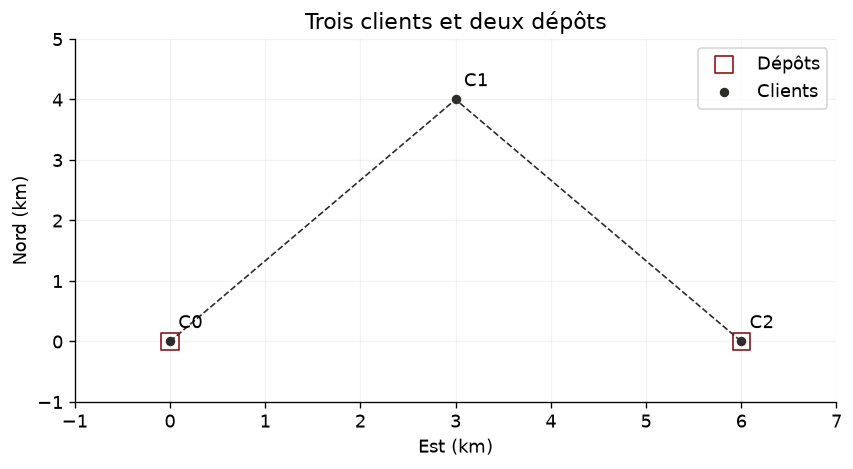

In [6]:
# Distances géométriques entre clients et dépôts
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(depots[:, 0], depots[:, 1], marker="s", s=110,
           facecolors="none", edgecolors=burgundy, label="Dépôts", zorder=3)
ax.scatter(clients[:, 0], clients[:, 1], color=ink, s=22, label="Clients", zorder=4)
for i, (x, y) in enumerate(clients):
    ax.annotate(f"C{i}", (x,y), xytext=(5,8), textcoords="offset points")
ax.plot([0,3,6],[0,4,0], "--", color=ink, linewidth=1)
ax.set(xlabel="Est (km)", ylabel="Nord (km)", xlim=(-1,7), ylim=(-1,5),
       title="Trois clients et deux dépôts")
ax.legend(); plt.show()

Le client C1 est à 5 km de chaque dépôt. Les autres clients sont situés sur un dépôt. Les segments représentent les distances à vol d'oiseau, sans réseau routier.

## Diapositive 8 — Débogage : le mauvais axe

Les différences ont la forme (3,2,2), avec les axes client, dépôt, coordonnée. Dans le fragment suivant, quelle information est additionnée ? Pourquoi la forme affichée ne suffit-elle pas à valider le résultat ? Corriger l'axe et contrôler C0 à la main.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



### Code à analyser

~~~python
mauvais = (ecarts ** 2).sum(axis=1)
print(mauvais.shape)  # (3, 2)
~~~

In [7]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 9 — Correction : sens des axes et coût mémoire

Le mauvais axe conserve accidentellement une forme (3,2). Les valeurs et les unités doivent aussi être contrôlées. Le traitement par lots réduit la mémoire temporaire, pas le nombre de comparaisons.

## Diapositive 10 — Problème 2 : retrouver un taux annuel

Le problème est fictif et sert à résoudre une équation. Un taux est une proportion : 0,1 signifie 10 %. Les versements sont en fin d'année.

Pour trois versements de 100 € aux années 1, 2 et 3 : $f(r)=\sum_{t=1}^3 100/(1+r)^t-250$. On cherche $f(r)=0$ pour $0\le r\le0{,}5$.

## Diapositive 11 — Chercher une racine avec brentq

brentq reçoit une fonction et deux bornes. La continuité et le changement de signe encadrent la racine. Le bilan est en euros, alors que sa variable est un taux.

In [8]:
annees = np.arange(1, 4)
versements = np.array([100., 100., 100.])

def bilan(taux):
    return (versements / (1 + taux) ** annees).sum() - 250

print(bilan(0), bilan(0.5))

50.0 -109.25925925925927


## Diapositive 12 — Exercice : résoudre et vérifier le taux

Écrire le pseudocode, chercher le taux avec brentq entre 0 et 0,5, afficher le taux en pourcentage puis vérifier le bilan et le montant actualisé.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [9]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 13 — Correction : un taux proche de 9,70 %

Le taux est voisin de 9,701 %. Le bilan recalculé est presque nul et la valeur actuelle des versements retrouve 250 euros.

In [10]:
taux = optimize.brentq(bilan, 0, 0.5)
print(f"{100 * taux:.2f} %")
print(bilan(taux))                  # proche de zéro
print((versements / (1+taux)**annees).sum())  # 250

9.70 %
5.684341886080802e-14
250.00000000000006


### Lecture du résultat

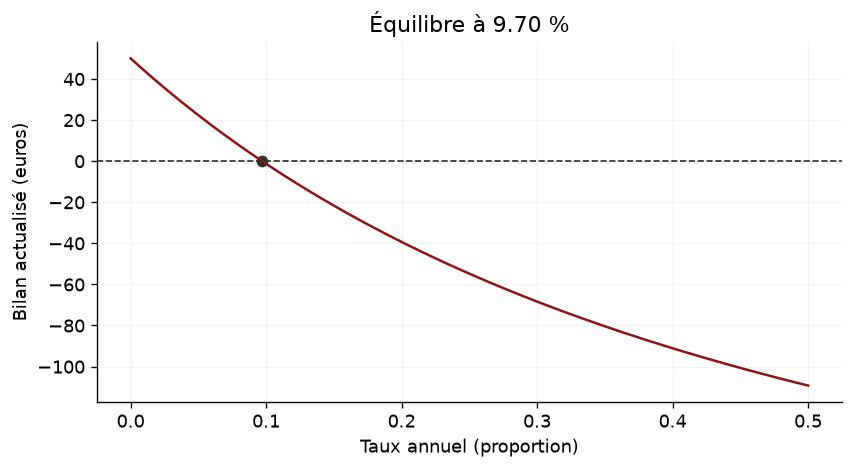

In [11]:
grille_taux = np.linspace(0, 0.5, 200)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grille_taux, [bilan(r) for r in grille_taux], color=burgundy)
ax.axhline(0, color=ink, linestyle="--", linewidth=1)
ax.scatter([taux], [0], color=ink)
ax.set(xlabel="Taux annuel (proportion)", ylabel="Bilan actualisé (euros)",
       title=f"Équilibre à {100*taux:.2f} %")
plt.show()

La fonction diminue et coupe zéro vers 9,70 %. Ce taux équilibre le montant initial et les trois versements actualisés.

## Diapositive 14 — Problème 3 : estimer le risque d'une perte

Une perte signifie 15K−20<0, donc K≤1. Écrire cette condition avant de simuler. Les hypothèses sont dix essais indépendants avec la même probabilité d'achat.

$K\sim\mathcal B(10;0{,}2)$ et $G=15K-20$ euros. Une journée déficitaire vérifie $K\le1$.

## Diapositive 15 — Exercice : simuler des journées

Simuler 100 000 jours avec rng.binomial(10, 0.2, size=100_000), calculer les bénéfices, compter les pertes avec np.count_nonzero et former leur fréquence. Écrire d'abord les étapes. Comparer avec stats.binom.cdf(1, n=10, p=0.2). Vérifier d'abord K=[0,1,2,3] à la main.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [12]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 16 — Correction : comparer simulation et probabilité

La probabilité exacte vaut 0,3758096384. La simulation approche ce résultat sans devoir lui être exactement égale.

In [13]:
rng = np.random.default_rng(2026)
achats = rng.binomial(n=10, p=0.2, size=100_000)
gains = 15 * achats - 20
nb_pertes = np.count_nonzero(gains < 0)
frequence = nb_pertes / len(gains)
proba_exacte = stats.binom.cdf(1, n=10, p=0.2)
print(frequence, proba_exacte)  # environ 0.376

0.37796 0.3758096384000002


### Lecture du résultat

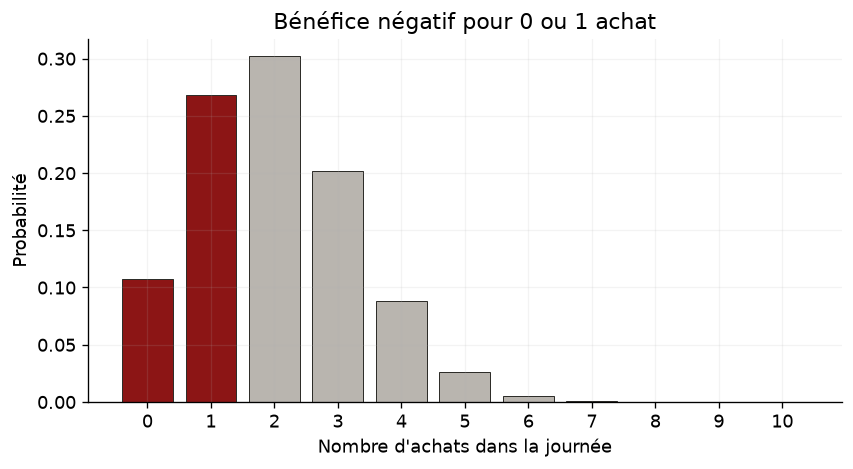

In [14]:
k_possibles = np.arange(11)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(k_possibles, stats.binom.pmf(k_possibles, n=10, p=0.2),
       color=[burgundy if k <= 1 else "#B9B5AF" for k in k_possibles],
       edgecolor=ink, linewidth=0.6)
ax.set(xlabel="Nombre d'achats dans la journée",
       ylabel="Probabilité", xticks=k_possibles,
       title="Bénéfice négatif pour 0 ou 1 achat")
plt.show()

Les deux premières barres représentent les journées déficitaires. Leurs probabilités totalisent environ 37,58 %. Le calcul exact sert de référence à la simulation.

## Diapositive 17 — Une fonction pour un lot de simulations

Un lot renvoie des effectifs, plutôt qu'une fréquence seule. On peut ensuite additionner les effectifs de plusieurs lots, même de tailles différentes.

In [15]:
def simuler_lot(graine, n_jours=25_000):
    rng_local = np.random.default_rng(graine)
    k = rng_local.binomial(10, 0.2, size=n_jours)
    pertes = int(np.count_nonzero(15 * k - 20 < 0))
    return pertes, n_jours

print(simuler_lot(2026))

(9478, 25000)


## Diapositive 18 — Concurrence et parallélisme

Les rectangles illustrent l'organisation des tâches, sans représenter des mesures de performance. La concurrence peut se produire sur un seul cœur.

## Diapositive 19 — Threads, processus et tâches asynchrones

Un processus a son espace mémoire. Des threads d'un même processus partagent les objets. Une tâche asyncio cède volontairement l'exécution lorsqu'elle attend.

## Diapositive 20 — Python, le GIL et les calculs NumPy

Le GIL concerne ici CPython classique. NumPy peut libérer ce verrou pendant des opérations natives. Éviter les conclusions universelles sur la vitesse ; les bibliothèques de calcul peuvent déjà utiliser plusieurs threads.

## Diapositive 21 — Distribuer des appels avec un pool de threads

map applique la fonction aux entrées ; la liste conserve l'ordre des entrées. with termine proprement le pool. Les travailleurs peuvent terminer dans un autre ordre.

## Diapositive 22 — Exercice : trois acquisitions indépendantes

La fonction ci-dessous simule une acquisition bloquante de 0,2 seconde. Écrire les étapes pour lancer les identifiants 1, 2 et 3 avec trois threads. Prévoir la liste renvoyée et comparer le temps total avec les appels séquentiels.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [16]:
import time

def acquisition(identifiant):
    time.sleep(0.2)
    return 10 * identifiant

identifiants = [1, 2, 3]

In [17]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 23 — Correction : faire progresser plusieurs attentes

La sortie reste [10,20,30]. Les durées sont mesurées, sans promettre un rapport fixe entre elles. L'exemple porte sur des attentes.

In [18]:
from concurrent.futures import ThreadPoolExecutor
from time import perf_counter

debut = perf_counter()
sequentiel = [acquisition(i) for i in identifiants]
duree_seq = perf_counter() - debut

debut = perf_counter()
with ThreadPoolExecutor(max_workers=3) as pool:
    concurrent = list(pool.map(acquisition, identifiants))
duree_threads = perf_counter() - debut
print(concurrent, duree_seq, duree_threads)  # [10, 20, 30]

[10, 20, 30] 0.6232360409994726 0.2089854590012692


## Diapositive 24 — Répartir les simulations entre processus

SeedSequence permet de dériver des flux adaptés aux calculs indépendants. Dans notre organisation, une graine est attribuée à un lot, ce qui évite une dépendance à l'ordre d'exécution.

In [19]:
graines = np.random.SeedSequence(2026).spawn(4)

## Diapositive 25 — Plusieurs processus : un fichier Python exécutable

Exécuter le fichier fourni dans un terminal ou avec la cellule de lancement du notebook. Les fonctions destinées aux processus résident dans un module importable. Le pool utilise explicitement spawn pour être portable.

### Programme fourni

~~~python
from concurrent.futures import ProcessPoolExecutor
from multiprocessing import get_context
from ch06_travailleurs import simuler_lot
import numpy as np

if __name__ == "__main__":
    graines = np.random.SeedSequence(2026).spawn(4)
    with ProcessPoolExecutor(
            max_workers=2, mp_context=get_context("spawn")) as pool:
        lots = list(pool.map(simuler_lot, graines))
    print(lots)  # couples (pertes, nombre de jours)
~~~

### Lancement du programme

Cette cellule fournie écrit le module et le programme dans un dossier temporaire, puis lance un interpréteur Python indépendant. Cela rend la fonction importable par les processus enfants. Les sorties séquentielle et parallèle doivent être identiques pour les mêmes lots.

In [20]:
from pathlib import Path
from tempfile import TemporaryDirectory
import subprocess, sys

module_fourni = '"""Fonction importable par les processus du chapitre 6."""\nimport numpy as np\n\ndef simuler_lot(graine, n_jours=25_000):\n    rng_local = np.random.default_rng(graine)\n    k = rng_local.binomial(10, 0.2, size=n_jours)\n    pertes = int(np.count_nonzero(15 * k - 20 < 0))\n    return pertes, n_jours\n\n'
programme_fourni = '"""Comparer les mêmes quatre lots en séquentiel et avec deux processus."""\nfrom concurrent.futures import ProcessPoolExecutor\nfrom multiprocessing import get_context\nfrom time import perf_counter\nimport numpy as np\nfrom ch06_travailleurs import simuler_lot\n\nif __name__ == "__main__":\n    graines = np.random.SeedSequence(2026).spawn(4)\n    debut = perf_counter()\n    reference = [simuler_lot(graine) for graine in graines]\n    duree_seq = perf_counter() - debut\n\n    debut = perf_counter()\n    with ProcessPoolExecutor(\n            max_workers=2, mp_context=get_context("spawn")) as pool:\n        lots = list(pool.map(simuler_lot, graines))\n    duree_processus = perf_counter() - debut\n\n    assert lots == reference\n    pertes = sum(lot[0] for lot in lots)\n    total = sum(lot[1] for lot in lots)\n    print("Lots identiques :", lots == reference)\n    print("Pertes / jours :", pertes, total)\n    print("Frequence :", pertes / total)\n    print("Secondes, sequentiel :", round(duree_seq, 4))\n    print("Secondes, processus :", round(duree_processus, 4))\n    print("Les temps incluent le demarrage et les echanges du pool.")\n'

with TemporaryDirectory(prefix="cours_ch06_") as dossier:
    chemin = Path(dossier)
    (chemin / "ch06_travailleurs.py").write_text(module_fourni, encoding="utf-8")
    script = chemin / "chapitre_06_processus.py"
    script.write_text(programme_fourni, encoding="utf-8")
    execution = subprocess.run([sys.executable, str(script)],
        cwd=chemin, text=True, capture_output=True,
        check=True, timeout=60)
    print(execution.stdout)


Lots identiques : True
Pertes / jours : 37685 100000
Frequence : 0.37685
Secondes, sequentiel : 0.0018
Secondes, processus : 0.0607
Les temps incluent le demarrage et les echanges du pool.



## Diapositive 26 — Exercice : réunir des résultats de tailles différentes

Deux lots renvoient (pertes, jours) : (100,1000) et (900,3000). Calculer la fréquence globale à la main. Comparer avec la moyenne simple des fréquences 0,1 et 0,3. Écrire le pseudocode, puis le calcul Python utilisant les effectifs.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [21]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 27 — Correction : additionner avant de diviser

La fréquence globale est 0,25. Une moyenne de fréquences doit tenir compte des dénominateurs.

In [22]:
lots_exemple = [(100, 1000), (900, 3000)]
pertes_total = sum(lot[0] for lot in lots_exemple)
jours_total = sum(lot[1] for lot in lots_exemple)
print(pertes_total / jours_total)  # 0.25

0.25


## Diapositive 28 — L'asynchronisme avec async et await

async def crée une coroutine. await attend un objet compatible ; le passage à une autre tâche se produit lorsque l'opération se suspend. gather organise plusieurs coroutines et préserve l'ordre des résultats.

## Diapositive 29 — Exercice : repérer une attente qui bloque

Le fragment suivant attend avec time.sleep dans une coroutine. Expliquer son effet sur la boucle d'événements, corriger l'attente puis proposer les étapes pour réunir les lectures 1, 2 et 3 avec gather.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



### Code à analyser

~~~python
import asyncio

async def lire_appareil(i):
    time.sleep(0.2)
    return 10 * i
~~~

In [23]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 30 — Correction : une attente coopérative

Le notebook lance la coroutine avec await. Dans un script indépendant, asyncio.run gère la boucle. Les sorties restent [10,20,30].

In [24]:
import asyncio

async def lire_appareil_async(i):
    await asyncio.sleep(0.2)
    return 10 * i

async def lectures():
    return await asyncio.gather(
        lire_appareil_async(1), lire_appareil_async(2),
        lire_appareil_async(3))

In [25]:
resultats_async = await lectures()
print(resultats_async)

[10, 20, 30]


## Diapositive 31 — Une mise à jour perdue

Il s'agit d'une trace possible, pas d'un programme destiné à reproduire une course de manière aléatoire. Les deux lectures du même ancien état entraînent une mise à jour perdue.

## Diapositive 32 — Protéger une section critique avec un verrou

Le paramètre _ reçoit l'entrée de map mais n'est pas utilisé. Le verrou protège toute la lecture-modification-écriture. Une autre conception consiste à éviter le compteur partagé.

In [26]:
from threading import Lock
etat = {"total": 0}
verrou = Lock()

def ajouter_un(_):
    with verrou:
        etat["total"] = etat["total"] + 1

with ThreadPoolExecutor(max_workers=3) as pool:
    list(pool.map(ajouter_un, range(1000)))
print(etat["total"])  # 1000

1000


## Diapositive 33 — Deadlock : deux tâches s'attendent

Tracer deux tâches et leurs ressources permet d'identifier le cycle. Le fragment de la diapositive suivante est à analyser ; la correction seule est exécutée.

## Diapositive 34 — Exercice : supprimer le cycle d'attente

Deux threads acquièrent les mêmes verrous dans des ordres opposés. Donner un entrelacement qui les bloque, proposer une règle d'acquisition commune, puis réécrire la seconde fonction.

~~~python
def operation_a():
    with verrou_1:
        with verrou_2:
            traiter_a()

def operation_b():
    with verrou_2:
        with verrou_1:
            traiter_b()
~~~

Ces fragments sont à analyser. La correction suivante sera exécutée.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [27]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 35 — Correction : un ordre commun pour les verrous

Les deux appels utilisent la même fonction et le même ordre de verrous. Ils renvoient A termine et B termine.

In [28]:
verrou_1, verrou_2 = Lock(), Lock()

def operation(nom):
    with verrou_1:
        with verrou_2:
            return nom + " termine"

with ThreadPoolExecutor(max_workers=2) as pool:
    print(list(pool.map(operation, ["A", "B"])))

['A termine', 'B termine']


## Diapositive 36 — Livelock : agir sans avancer

Deux personnes dans un couloir changent toutes les deux de côté lorsque leurs côtés sont identiques. Le programme ci-dessous simule quatre décisions simultanées. Tracer les positions et proposer une règle qui permette de se croiser. Cette simulation représente les décisions ; elle n'exécute pas deux threads.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [29]:
cotes = [0, 0]  # même côté du couloir
for tour in range(4):
    if cotes[0] == cotes[1]:
        cotes = [1 - cote for cote in cotes]
    print(cotes)  # [1,1], [0,0], [1,1], [0,0]

[1, 1]
[0, 0]
[1, 1]
[0, 0]


In [30]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 37 — Correction : donner une priorité

Une priorité casse la symétrie. Cette correction résout le modèle du couloir ; elle illustre une règle à concevoir selon le système réel.

In [31]:
cotes = [0, 0]
if cotes[0] == cotes[1]:
    cotes[1] = 1 - cotes[1]
print(cotes)  # [0, 1] : les deux personnes peuvent se croiser

[0, 1]


## Diapositive 38 — Exercice : choisir une organisation du calcul

Proposer une méthode et justifier son choix pour :

1. Convertir un million de mesures avec une formule numérique.
2. Attendre vingt réponses avec une bibliothèque réseau bloquante.
3. Exécuter de longues boucles Python indépendantes.
4. Attendre avec une bibliothèque proposant des fonctions async.

Indiquer les mesures de temps nécessaires et les données susceptibles d'être partagées.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [32]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 39 — Correction : choisir selon le travail réel

Ces choix sont des points de départ pour mesurer. Ils ne promettent aucune accélération universelle.

## Diapositive 40 — Deuxième partie : une table de commandes

Le jeu complet contient huit commandes. Une ligne représente une commande, les prix sont en euros et les délais en jours. Les valeurs manquantes sont intentionnelles.

## Diapositive 41 — DataFrame, Series et index

Le DataFrame est créé dans le notebook. La sélection d'une seule colonne produit une Series et conserve les étiquettes des lignes.

In [33]:
commandes = pd.DataFrame({
    "id": [101, 102, 103, 104, 105, 106, 107, 108],
    "ville": ["Tunis", "Sfax", "Tunis", "Sfax",
              "Tunis", "Sousse", "Sousse", "Sfax"],
    "quantite": [2, 1, 3, np.nan, 1, 2, 1, 4],
    "prix": [10., 20., 10., 20., 15., 12., 12., 20.],
    "delai": [2., 3., np.nan, 4., 2., 5., np.nan, 3.]
})
print(commandes["ville"].head(3))

0    Tunis
1     Sfax
2    Tunis
Name: ville, dtype: object


## Diapositive 42 — Examiner une table avant de calculer

La table contient huit lignes et cinq colonnes, une quantité absente et deux délais absents. Les huit identifiants sont uniques.

In [34]:
print(commandes.head(4))       # premières lignes
print(commandes.shape)         # (8, 5)
print(commandes.dtypes)        # type par colonne
print(commandes.isna().sum())  # absences par colonne
print(commandes["id"].is_unique)

    id  ville  quantite  prix  delai
0  101  Tunis       2.0  10.0    2.0
1  102   Sfax       1.0  20.0    3.0
2  103  Tunis       3.0  10.0    NaN
3  104   Sfax       NaN  20.0    4.0
(8, 5)
id            int64
ville        object
quantite    float64
prix        float64
delai       float64
dtype: object
id          0
ville       0
quantite    1
prix        0
delai       2
dtype: int64
True


## Diapositive 43 — Sélectionner par étiquette ou par position

loc sélectionne par étiquette ou masque, iloc par position. Le filtre conserve les étiquettes d'origine. Ne pas supposer qu'une étiquette 0 existe dans une table filtrée.

In [35]:
print(commandes.loc[0, "ville"])        # Tunis
print(commandes.iloc[0, 1])            # Tunis
print(commandes[["ville", "prix"]].head(2))
masque = commandes["ville"] == "Tunis"
print(commandes.loc[masque, ["id", "quantite"]])

Tunis
Tunis
   ville  prix
0  Tunis  10.0
1   Sfax  20.0
    id  quantite
0  101       2.0
2  103       3.0
4  105       1.0


## Diapositive 44 — Exercice : calculer et filtrer des montants

Écrire les étapes puis ajouter une colonne montant=quantite×prix. Sélectionner les commandes de Tunis d'au moins 20 euros, avec seulement id, ville et montant. Vérifier les commandes 101 et 103 à la main.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [36]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 45 — Correction : calculer une colonne, puis sélectionner

Deux commandes répondent aux conditions : 101 pour 20 euros et 103 pour 30 euros. Leur somme vaut 50 euros.

In [37]:
commandes["montant"] = commandes["quantite"] * commandes["prix"]
masque = ((commandes["ville"] == "Tunis")
          & (commandes["montant"] >= 20))
selection = commandes.loc[masque, ["id", "ville", "montant"]]
print(selection)
# id 101 : 20 euros ; id 103 : 30 euros

    id  ville  montant
0  101  Tunis     20.0
2  103  Tunis     30.0


## Diapositive 46 — Débogage : modifier une sélection

Une correction confirmée donne un délai de 4 jours à la commande 103. Le code suivant fait une affectation chaînée. Identifier l'objet intermédiaire, réécrire en une opération loc, puis vérifier le résultat.

~~~python
commandes[commandes['id'] == 103]['delai'] = 4
~~~

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [38]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 47 — Correction : une affectation explicite

La commande 103 a un délai corrigé de 4 jours dans corrigees. La table commandes reste la référence d'origine pour la suite.

In [39]:
corrigees = commandes.copy()
masque_103 = corrigees["id"] == 103
corrigees.loc[masque_103, "delai"] = 4
print(corrigees.loc[masque_103, ["id", "delai"]])

    id  delai
2  103    4.0


## Diapositive 48 — Deux absences, deux décisions différentes

La politique choisie garde les commandes dont la quantité est connue. Un délai absent n'empêche pas le calcul du chiffre d'affaires. Le nombre d'observations utilisé pour chaque mesure doit être explicite.

## Diapositive 49 — Exercice : conserver les commandes exploitables

Partir de commandes, la table initiale. Écrire les étapes pour écarter seulement les quantités absentes et créer valides sans modifier commandes. Compter les lignes écartées, les délais absents, les délais présents et le chiffre d'affaires observé. Expliquer le périmètre de ce total.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [40]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 50 — Correction : un total et son périmètre

Le chiffre d'affaires observé est 201 euros pour sept commandes. Cinq délais sont observés. Le résultat n'est pas le chiffre d'affaires de toutes les commandes.

In [41]:
valides = commandes.dropna(subset=["quantite"]).copy()
print(len(commandes) - len(valides))  # 1 ligne écartée
print(valides["delai"].isna().sum())  # 2 délais absents
print(valides["montant"].sum())      # 201 euros
print(valides["delai"].count())      # 5 délais observés

1
2
201.0
5


## Diapositive 51 — Regrouper les commandes par ville

Une agrégation change le niveau de détail : on passe d'une ligne par commande à une ligne par ville. Chaque nouveau nom de colonne est associé à une colonne source et à une opération.

## Diapositive 52 — Exercice : résumer les ventes par ville

Construire une ligne par ville avec le nombre de commandes, le chiffre d'affaires observé, la moyenne des délais présents et leur nombre. Utiliser size pour compter les lignes et count pour compter les valeurs présentes. Vérifier Tunis à la main et réconcilier le total des villes.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [42]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 53 — Correction : des résumés avec leurs effectifs

Sfax : 100 euros ; Sousse : 36 ; Tunis : 65. Les délais sont calculés sur 2, 1 et 2 valeurs respectivement. La moyenne de Sousse repose sur une seule mesure.

In [43]:
resume = valides.groupby("ville", as_index=False).agg(
    n_commandes=("id", "size"), ca=("montant", "sum"),
    delai_moyen=("delai", "mean"), n_delais=("delai", "count"))
print(resume)
print(resume.sort_values("ca", ascending=False))

    ville  n_commandes     ca  delai_moyen  n_delais
0    Sfax            2  100.0          3.0         2
1  Sousse            2   36.0          5.0         1
2   Tunis            3   65.0          2.0         2
    ville  n_commandes     ca  delai_moyen  n_delais
0    Sfax            2  100.0          3.0         2
2   Tunis            3   65.0          2.0         2
1  Sousse            2   36.0          5.0         1


## Diapositive 54 — Débogage : pandas aligne les étiquettes

Les prix et les quantités ci-dessous ont des étiquettes A et B dans des ordres différents. Prévoir prix * quantites, puis comparer avec une multiplication des valeurs NumPy dans leur ordre actuel. Expliquer les correspondances nécessaires.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [44]:
prix = pd.Series([10., 20.], index=["A", "B"])
quantites = pd.Series([3., 2.], index=["B", "A"])
print(prix)
print(quantites)

A    10.0
B    20.0
dtype: float64
B    3.0
A    2.0
dtype: float64


In [45]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 55 — Correction : étiquettes ou positions

Les bonnes valeurs sont A : 20 et B : 60. Le calcul par position sans alignement préalable donne [30,40], ce qui associe les mauvais produits.

In [46]:
print(prix * quantites)  # A : 20 ; B : 60
print(prix.to_numpy() * quantites.to_numpy())  # [30. 40.]
q_alignees = quantites.reindex(prix.index)
print(prix.to_numpy() * q_alignees.to_numpy())  # [20. 60.]

A    20.0
B    60.0
dtype: float64
[30. 40.]
[20. 60.]


## Diapositive 56 — Lire un CSV et convertir des colonnes

Le notebook fournit aussi le contenu du CSV en mémoire pour rester autonome. Le fichier du pack contient exactement les mêmes données. Une conversion impossible devient manquante et doit être auditée.

In [47]:
from io import StringIO
contenu_csv = """id;date;ville;quantite;prix;delai
101;2026-10-01;Tunis;2;10;2
102;2026-10-01;Sfax;1;20;3
103;2026-10-02;Tunis;3;10;
104;2026-10-02;Sfax;;20;4
105;2026-10-03;Tunis;1;15;2
106;2026-10-03;Sousse;2;12;5
107;2026-10-04;Sousse;1;12;
108;2026-10-04;Sfax;4;20;3
"""
table = pd.read_csv(StringIO(contenu_csv), sep=";")
table["date"] = pd.to_datetime(table["date"], errors="coerce")
table["quantite"] = pd.to_numeric(table["quantite"], errors="coerce")
print(table.head(3))
print(table.isna().sum())

    id       date  ville  quantite  prix  delai
0  101 2026-10-01  Tunis       2.0    10    2.0
1  102 2026-10-01   Sfax       1.0    20    3.0
2  103 2026-10-02  Tunis       3.0    10    NaN
id          0
date        0
ville       0
quantite    1
prix        0
delai       2
dtype: int64


## Diapositive 57 — Exercice final : appliquer une remise et résumer

Les commandes d'au moins trois articles ont une remise de 10 %. À partir de valides, écrire les étapes puis utiliser np.where pour créer des coefficients 0,9 ou 1. Ajouter net et résumer ses sommes par ville. Vérifier manuellement les commandes 103 et 108, puis le total des remises.

### Votre démarche

Écrire le pseudocode ou l'explication, puis vérifier un petit cas à la main.

Votre réponse :



In [48]:
# Votre essai : pseudocode, puis programme ou correction.


## Diapositive 58 — Correction : NumPy calcule, pandas organise

Les montants nets par ville sont 92, 36 et 62 euros. Leur somme vaut 190 euros. Les deux remises totalisent 11 euros.

In [49]:
coefficients = np.where(valides["quantite"] >= 3, 0.9, 1.)
valides["net"] = valides["montant"] * coefficients
nets_ville = valides.groupby("ville", as_index=False).agg(
    net=("net", "sum"))
print(nets_ville)           # Sfax 92 ; Sousse 36 ; Tunis 62
print(valides["net"].sum())  # 190 euros
print((valides["montant"] - valides["net"]).sum())  # 11

    ville   net
0    Sfax  92.0
1  Sousse  36.0
2   Tunis  62.0
190.0
11.0


### Lecture du résultat

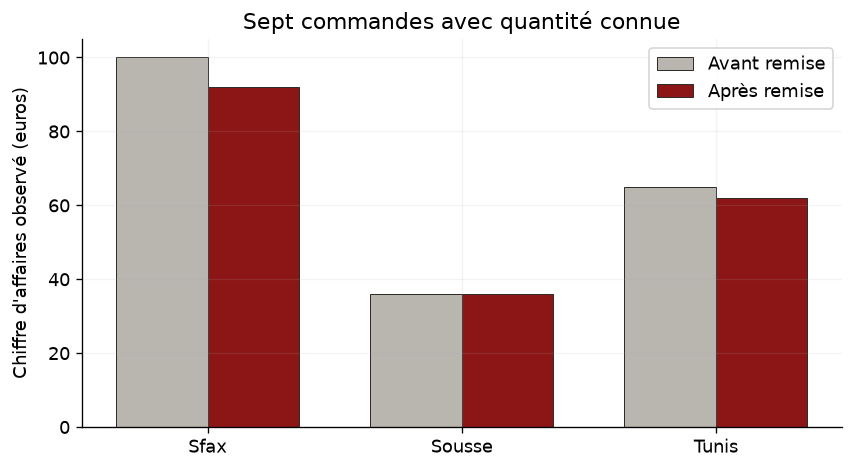

In [50]:
comparaison = valides.groupby("ville")[["montant","net"]].sum()
positions = np.arange(len(comparaison))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(positions-0.18, comparaison["montant"], width=0.36, color="#B9B5AF",
       edgecolor=ink, linewidth=0.6, label="Avant remise")
ax.bar(positions+0.18, comparaison["net"], width=0.36, color=burgundy,
       edgecolor=ink, linewidth=0.6, label="Après remise")
ax.set(xticks=positions, xticklabels=comparaison.index,
       ylabel="Chiffre d'affaires observé (euros)",
       title="Sept commandes avec quantité connue")
ax.legend(); plt.show()

Le chiffre d'affaires diminue de 8 euros à Sfax et de 3 euros à Tunis. Il reste inchangé à Sousse. La somme des montants nets vaut 190 euros.

## Vérifications finales

- Les affectations sont [0, 0, 1] ; les carrés des distances du client central sont [25, 25].
- Le taux équilibre les versements actualisés avec les 250 euros initiaux.
- La probabilité exacte de perte vaut environ 0,37581 ; la fréquence simulée fluctue.
- Les mêmes lots donnent les mêmes effectifs en séquentiel et dans le pool de processus.
- Le compteur protégé atteint 1000 ; les deux appels qui ordonnent leurs verrous terminent.
- Sept commandes contribuent aux 201 euros observés ; cinq délais sont présents.
- Après remise, les montants nets totalisent 190 euros.

## Pour prolonger : contrôler les distances avec SciPy

La fonction cdist(A, B) du module scipy.spatial.distance calcule les distances euclidiennes entre chaque ligne de A et chaque ligne de B. Elle renvoie une matrice de forme (nombre de lignes de A, nombre de lignes de B). Comparer son résultat avec la construction NumPy.


In [51]:
from scipy.spatial.distance import cdist
distances_scipy = cdist(clients, depots)
print(distances_scipy)
assert np.allclose(distances_scipy ** 2, distances2)

[[0. 6.]
 [5. 5.]
 [6. 0.]]


## Références

[NumPy : indexation](https://numpy.org/doc/stable/user/basics.indexing.html),
[NumPy : tirages parallèles](https://numpy.org/doc/stable/reference/random/parallel.html),
[SciPy : brentq](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html),
[SciPy : cdist](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cdist.html),
[Python : concurrent.futures](https://docs.python.org/3/library/concurrent.futures.html),
[Python : multiprocessing](https://docs.python.org/3/library/multiprocessing.html),
[Python : asyncio](https://docs.python.org/3/library/asyncio-task.html),
[Oracle : livelock](https://docs.oracle.com/javase/tutorial/essential/concurrency/starvelive.html),
[pandas : tutoriels](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html).
